In [27]:
import matplotlib.pyplot as plt
import pandas as pd 
import seaborn as sns


In [4]:

data_path=r'S:\interview_assements\spotter_ai_assessment\data\train-test.csv'
df = pd.read_csv(data_path)

df.shape

(48000, 14)

In [5]:
df.head()


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [7]:
df.describe(include="all")

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
count,48000,48000,48000,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,48000,47700.000000,48000,47626.000000,48000.000000,48000.000000
unique,48000,64,64,NaN,NaN,NaN,NaN,NaN,3,NaN,304,NaN,NaN,NaN
top,TR-000001,Oklahoma City,Lexington,NaN,NaN,NaN,NaN,NaN,Dry Van,NaN,2025-06-17,NaN,NaN,NaN
freq,1,1242,1197,NaN,NaN,NaN,NaN,NaN,27202,NaN,198,NaN,NaN,NaN
mean,NaN,NaN,NaN,35.647545,-90.928964,35.641175,-90.857310,1135.856654,NaN,31028.844004,NaN,1.083387,2.062468,2373.980682
std,NaN,NaN,NaN,4.315285,13.482431,4.317199,13.476589,728.564416,NaN,9391.440620,NaN,0.168091,0.291391,1486.493245
min,NaN,NaN,NaN,28.357650,-121.698490,28.357650,-121.698490,70.000000,NaN,-47500.000000,NaN,0.676390,0.692280,57.220000
25%,NaN,NaN,NaN,31.986910,-98.400590,31.986910,-98.400590,550.400000,NaN,25800.000000,NaN,0.949670,1.891030,1251.555000
50%,NaN,NaN,NaN,35.294790,-88.089150,35.294790,-87.528710,953.300000,NaN,31436.500000,NaN,1.055800,2.055750,2030.760000
75%,NaN,NaN,NaN,39.411040,-83.285060,39.411040,-83.285060,1645.525000,NaN,37018.000000,NaN,1.219590,2.221685,3330.750000


In [8]:
min_date = df['date'].min()
max_date = df['date'].max()
print(f"Date range: {min_date} to {max_date}")

Date range: 2025-01-01 to 2025-10-31


In [9]:
#Missing data analysis

In [10]:
df.isnull().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

In [11]:
missing = df.isnull().mean()*100

missing.sort_values(ascending=False)

market_index    0.779167
weight          0.625000
delivery        0.000000
pickup_lat      0.000000
load_id         0.000000
pickup          0.000000
delivery_lat    0.000000
pickup_lon      0.000000
distance        0.000000
delivery_lon    0.000000
equipment       0.000000
date            0.000000
quote_signal    0.000000
posted_rate     0.000000
dtype: float64

In [12]:
#duplicate checking

In [13]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate IDs:", df["load_id"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


In [14]:
#the target distribution

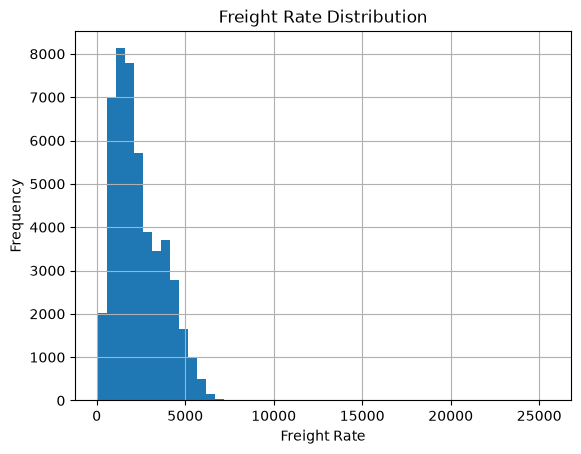

In [15]:

df["posted_rate"].hist(bins=50)

plt.xlabel("Freight Rate")
plt.ylabel("Frequency")
plt.title("Freight Rate Distribution")
plt.show()

In [16]:
print(df["posted_rate"].describe())
print(df["posted_rate"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64
0.25    1251.5550
0.50    2030.7600
0.75    3330.7500
0.90    4365.8230
0.95    4953.7665
0.99    5972.8340
Name: posted_rate, dtype: float64


In [17]:
for col in ["pickup", "delivery", "equipment"]:
    print(col)
    print(df[col].value_counts())

pickup
pickup
Oklahoma City    1242
Lexington        1209
Bakersfield      1193
Fort Wayne       1170
Hartford         1150
                 ... 
Detroit           337
Washington        337
St. Louis         318
Las Vegas         277
Dallas            276
Name: count, Length: 64, dtype: int64
delivery
delivery
Lexington      1197
Fort Wayne     1176
Baton Rouge    1167
Bakersfield    1156
Hartford       1143
               ... 
St. Louis       344
Birmingham      318
Detroit         307
Dallas          306
Las Vegas       292
Name: count, Length: 64, dtype: int64
equipment
equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64


In [18]:
df["date"] = pd.to_datetime(df["date"])

print(df["date"].min())
print(df["date"].max())

print(df.groupby(
    df["date"].dt.month
)["posted_rate"].agg(["mean", "median", "count"]))

2025-01-01 00:00:00
2025-10-31 00:00:00
             mean    median  count
date                              
1     2255.967048  1915.200   4918
2     2273.804801  1994.250   4337
3     2372.268092  2022.920   5036
4     2372.162308  2044.240   4819
5     2421.776342  2065.510   4913
6     2497.030115  2120.220   4783
7     2415.162030  2059.145   4912
8     2338.407661  2015.730   4759
9     2406.374013  2057.130   4670
10    2379.051374  2035.900   4853


In [19]:
#outliers and feature relationships

In [20]:
# Top 20 highest freight rates
top_rates = df.nlargest(20, "posted_rate")

print(
    top_rates[
        [
            "pickup",
            "delivery",
            "distance",
            "equipment",
            "weight",
            "market_index",
            "quote_signal",
            "posted_rate"
        ]
    ].to_string(index=False)
)

       pickup      delivery  distance equipment  weight  market_index  quote_signal  posted_rate
  Bakersfield      Hartford    2829.8   Dry Van 33153.0       1.16556       1.83188     25533.00
      Phoenix      Syracuse    2810.9   Dry Van 33674.0       1.04877       2.16284     24294.98
  Los Angeles      Syracuse    2786.0    Reefer 30322.0       0.98678       1.85370     24140.21
         Reno  Philadelphia    2777.6    Reefer 33158.0       1.15070       2.15601     23662.71
   Charleston       Phoenix    2552.5   Dry Van 25665.0       1.20224       1.81289     23580.42
       Tucson       Raleigh    2423.3   Dry Van 30972.0       1.32894       1.97112     22755.66
      Phoenix    Charleston    2527.9    Reefer 36840.0       1.03241       2.07342     22534.65
   Montgomery        Fresno    2283.4   Dry Van 32447.0       0.98502       1.93645     20361.89
    Baltimore Oklahoma City    1760.3    Reefer 29521.0       1.00464       2.28753     20132.37
       Boston   Bakersfield   

In [ ]:
#Freight rate versus distance

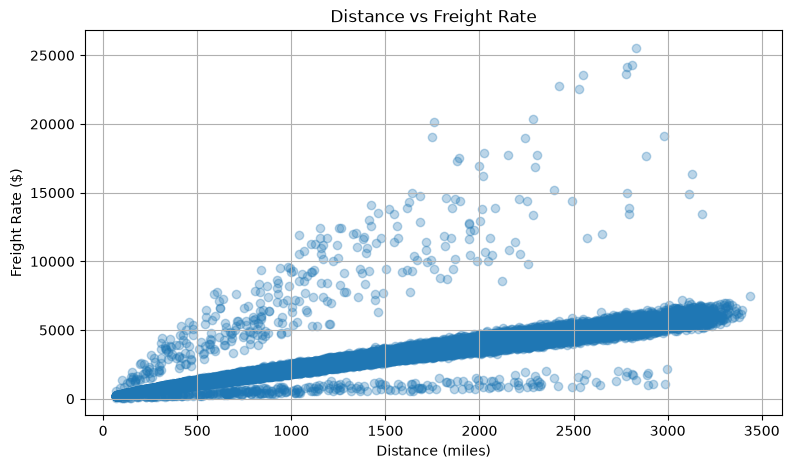

In [22]:

plt.figure(figsize=(9, 5))

plt.scatter(
    df["distance"],
    df["posted_rate"],
    alpha=0.3
)

plt.xlabel("Distance (miles)")
plt.ylabel("Freight Rate ($)")
plt.title("Distance vs Freight Rate")

plt.grid()
plt.show()

In [ ]:
# Freight rate by equipment

In [23]:
equipment_analysis = (
    df.groupby("equipment")["posted_rate"]
    .agg(["count", "mean", "median", "std"])
)

print(equipment_analysis)

           count         mean    median          std
equipment                                           
Dry Van    27202  2271.548686  1953.035  1423.029914
Flatbed     8753  2445.087223  2076.810  1505.053087
Reefer     12045  2553.636939  2196.670  1589.670824


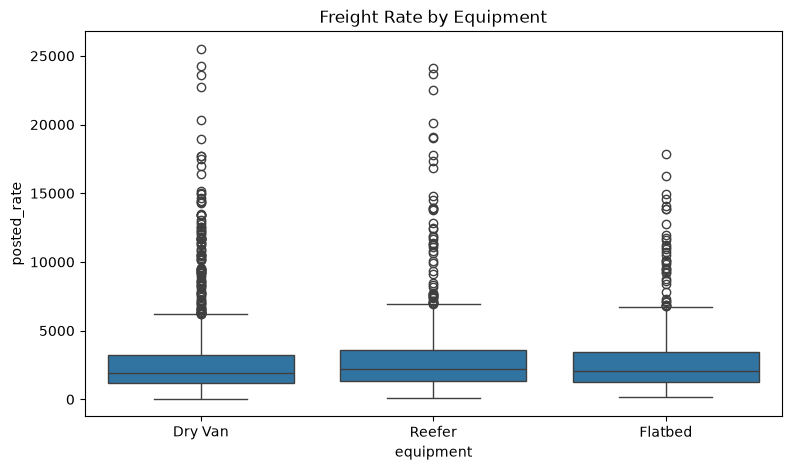

In [26]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="equipment",
    y="posted_rate"
)

plt.title("Freight Rate by Equipment")
plt.show()

In [ ]:
# Experiment 4: Numerical correlation

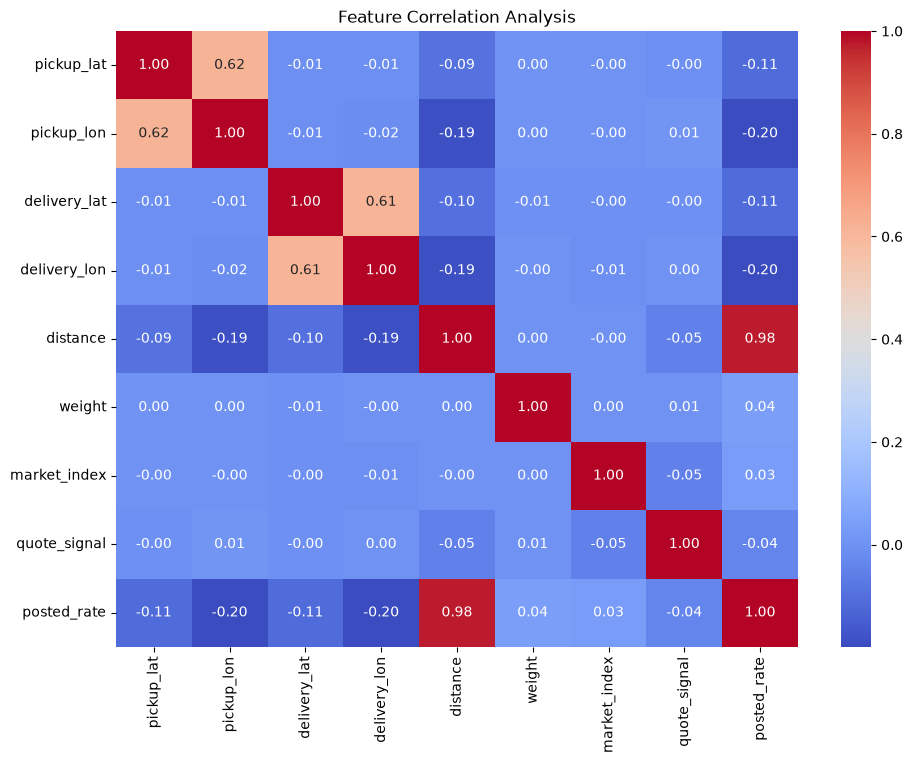

In [28]:
numerical_cols = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "posted_rate"
]

correlation = df[numerical_cols].corr(
    method="spearman"
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Analysis")
plt.show()